In [2]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
warnings.filterwarnings('ignore')

In [3]:
datafolder = "../data"
spadl_h5   = os.path.join(datafolder, "women-statsbomb3.h5")

## Load factor scores

In [4]:
efa_df = pd.read_hdf(spadl_h5, "efa_tempo_index")
print(f"Rows: {len(efa_df):,}")
print(efa_df.columns.tolist())
efa_df.head(3)

Rows: 39,995
['game_id', 'possession', 'possession_team_id', 'tournament', 'gender', 'TI_efa', 'TI_horst', 'F1', 'F2', 'F3']


,game_id,possession,possession_team_id,tournament,gender,TI_efa,TI_horst,F1,F2,F3
0,4020846,2,865,WEURO2025,Women,0.122384,1.143743,0.122384,0.414033,0.007227
1,4020846,4,865,WEURO2025,Women,0.375292,0.737501,0.375292,0.134878,-0.014533
2,4020846,5,865,WEURO2025,Women,0.009955,1.003642,0.009955,1.426399,1.172717


## Compare clustering methods and select the final pace-state model

K-means, Gaussian mixture modelling (GMM), and K-medians are first evaluated
for `K=2–8`. The number of clusters is selected from agreement between the
silhouette maxima and, for GMM, the minimum BIC. At the selected K, methods
are compared using 30 repeated 80/20 holdouts grouped by match, so possessions
from one match never occur in both training and validation data. Held-out
silhouette, Calinski–Harabasz, Davies–Bouldin, and label-stability ARI are
ranked jointly. Solutions must retain mean ARI ≥ 0.90, a smallest cluster
share ≥ 5%, and exactly `K−1` decision boundaries so pace states remain
contiguous and ordered on the PPI axis. BIC is not compared across methods because their objective
functions differ.

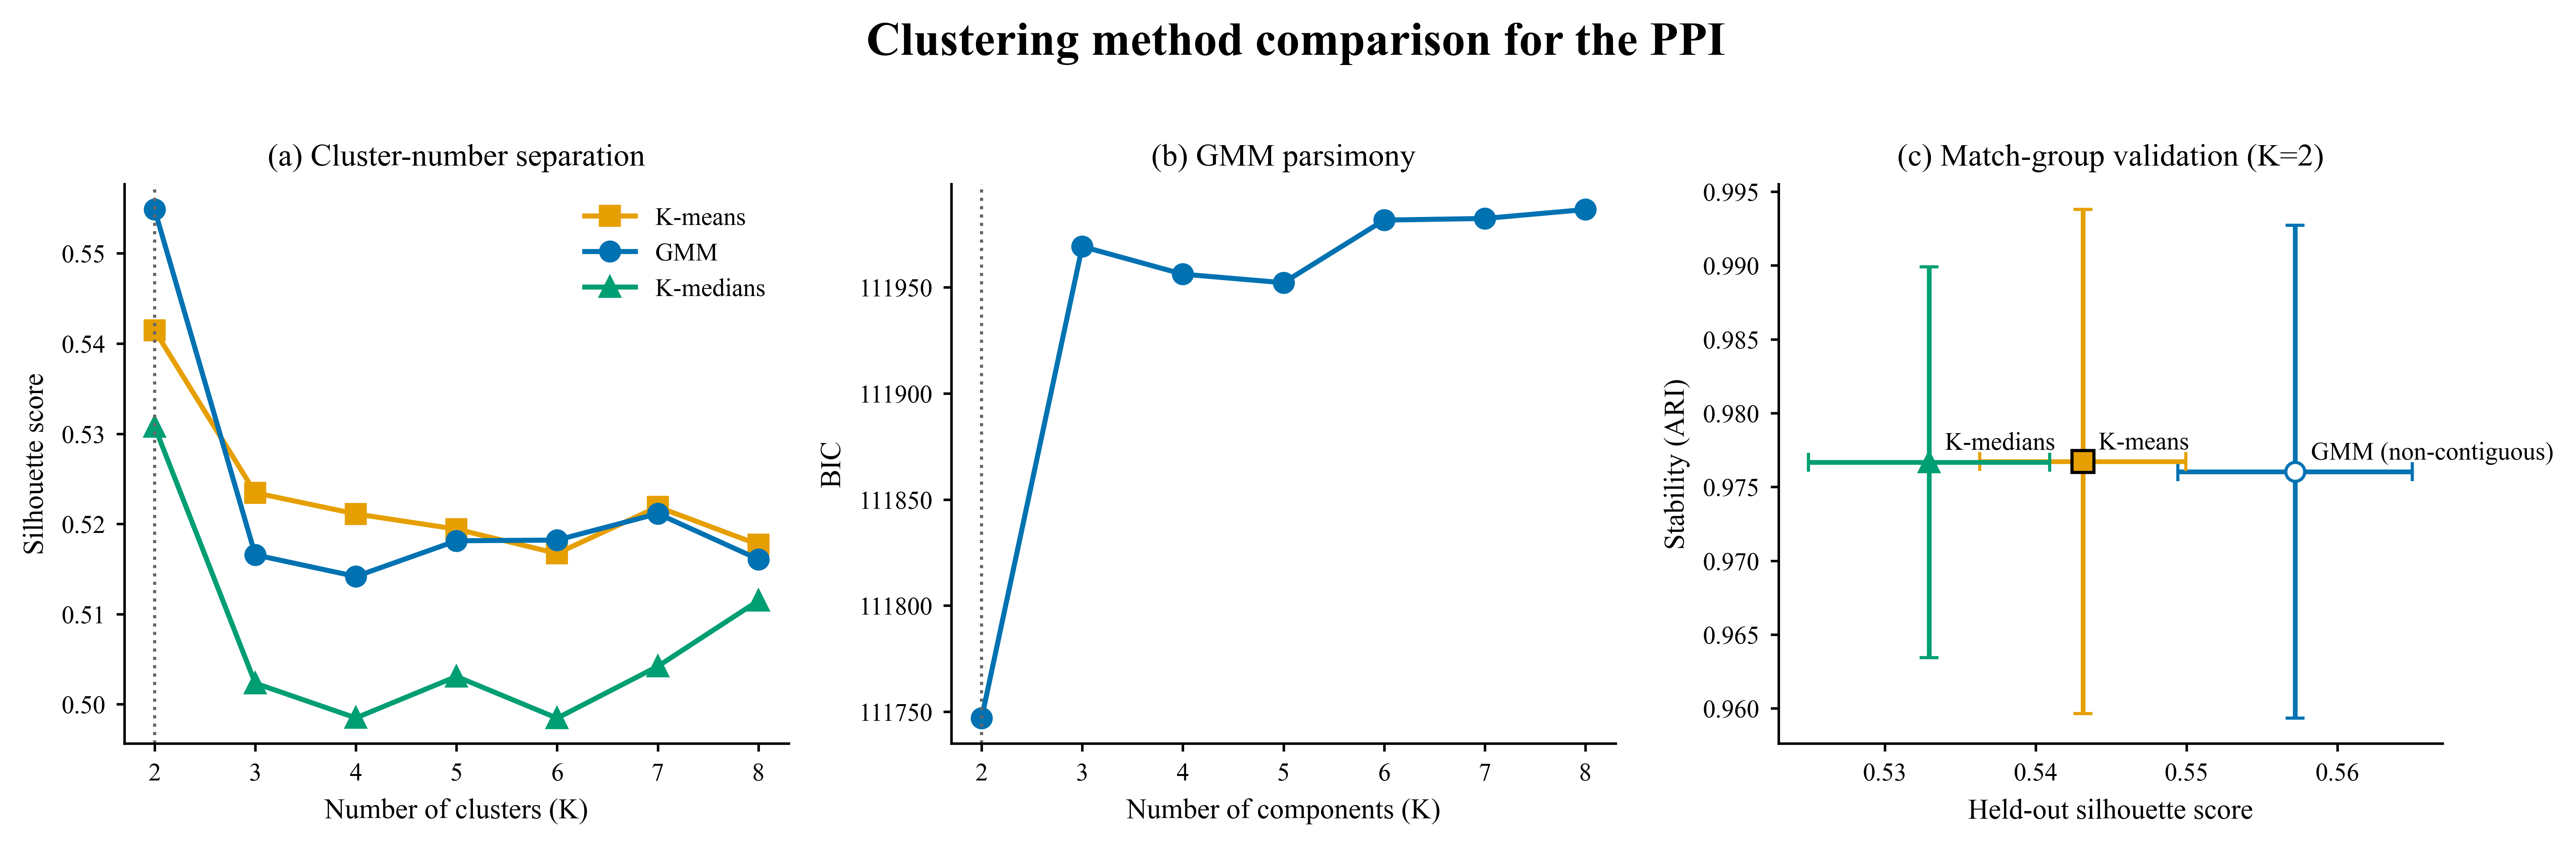

=== K selection ===
K-means   : silhouette-optimal K=2
GMM       : silhouette-optimal K=2
K-medians : silhouette-optimal K=2
GMM       : BIC-optimal K=2
Selected K: 2

=== Repeated match-group validation ===
   method  silhouette_mean  silhouette_sd  calinski_harabasz_mean  davies_bouldin_mean  stability_ari_mean  stability_ari_sd  min_cluster_share_mean  boundary_count  boundary_mean  boundary_sd  mean_rank  eligible
  K-means           0.5431         0.0068              12078.9846               0.6337              0.9767            0.0171                  0.3851               1        -0.1855       0.0165        1.5      True
      GMM           0.5572         0.0078               8990.5930               0.5891              0.9760            0.0167                  0.1980               2        -0.7619       0.0222        2.0     False
K-medians           0.5329         0.0080              11815.9101               0.6429              0.9767            0.0132                  0.4543  

In [5]:
# Prepare features for TI_horst
X_horst = efa_df[['TI_horst']].dropna()
meta_horst = efa_df.loc[X_horst.index, ["game_id","possession","possession_team_id", "tournament","gender"]]

from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, calinski_harabasz_score,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import BaseEstimator, ClusterMixin

class KMedians1D(BaseEstimator, ClusterMixin):
    """Robust 1-D K-medians with multiple starts and an L1 objective."""
    def __init__(self, n_clusters=3, max_iter=300, n_init=20, random_state=42):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.n_init = n_init
        self.random_state = random_state
        self.cluster_centers_ = None
        self.labels_ = None

    def fit(self, X, y=None):
        x = np.asarray(X, dtype=float).ravel()
        rng = np.random.default_rng(self.random_state)
        best_loss, best_centers, best_labels = np.inf, None, None
        for init in range(self.n_init):
            if init == 0:
                centers = np.quantile(x, (np.arange(self.n_clusters) + 0.5) / self.n_clusters)
            else:
                centers = np.sort(rng.choice(x, size=self.n_clusters, replace=False))
            for _ in range(self.max_iter):
                distances = np.abs(x[:, None] - centers[None, :])
                labels = distances.argmin(axis=1)
                new_centers = centers.copy()
                for k in range(self.n_clusters):
                    if np.any(labels == k):
                        new_centers[k] = np.median(x[labels == k])
                    else:
                        new_centers[k] = x[np.argmax(distances.min(axis=1))]
                new_centers.sort()
                if np.allclose(centers, new_centers, rtol=0, atol=1e-10):
                    break
                centers = new_centers
            labels = np.abs(x[:, None] - centers[None, :]).argmin(axis=1)
            loss = np.abs(x - centers[labels]).sum()
            if loss < best_loss:
                best_loss, best_centers, best_labels = loss, centers.copy(), labels.copy()
        self.cluster_centers_ = best_centers.reshape(-1, 1)
        self.labels_ = best_labels
        self.inertia_ = best_loss
        return self

    def fit_predict(self, X, y=None):
        return self.fit(X).labels_

    def predict(self, X):
        x = np.asarray(X, dtype=float).ravel()
        distances = np.abs(x[:, None] - self.cluster_centers_.ravel()[None, :])
        return np.argmin(distances, axis=1)

METHODS = ('kmeans', 'gmm', 'kmedians')
METHOD_LABELS = {'kmeans': 'K-means', 'gmm': 'GMM', 'kmedians': 'K-medians'}
K_RANGE = range(2, 9)
RANDOM_STATE = 2025

def _make_clusterer(method, k, seed=RANDOM_STATE):
    if method == 'kmeans':
        return KMeans(n_clusters=k, random_state=seed, n_init=20)
    if method == 'gmm':
        return GaussianMixture(n_components=k, covariance_type='full',
                               random_state=seed, n_init=10, reg_covar=1e-6)
    return KMedians1D(n_clusters=k, n_init=20, random_state=seed)

def _decision_boundaries(model):
    lo, hi = X_horst['TI_horst'].quantile([0.001, 0.999])
    grid = np.linspace(lo, hi, 30_001).reshape(-1, 1)
    labels = model.predict(grid)
    cuts = np.flatnonzero(np.diff(labels) != 0)
    return ((grid[cuts, 0] + grid[cuts + 1, 0]) / 2).tolist()

def _decision_boundary(model, method):
    if method == 'gmm':
        centres = np.sort(model.means_.ravel())
    else:
        centres = np.sort(model.cluster_centers_.ravel())
    cuts = _decision_boundaries(model)
    midpoint = centres.mean()
    return np.nan if len(cuts) == 0 else min(cuts, key=lambda b: abs(b - midpoint))

# Stage 1: select K. Silhouette is comparable for all three methods; BIC is
# used only within GMM because centroid and mixture objectives are different.
sil_scores = {method: [] for method in METHODS}
bic_scores_gmm = []
full_models = {}
for k in K_RANGE:
    for method in METHODS:
        model = _make_clusterer(method, k).fit(X_horst)
        full_models[(method, k)] = model
        labels = model.predict(X_horst)
        sil = silhouette_score(X_horst, labels, sample_size=10_000,
                               random_state=RANDOM_STATE)
        sil_scores[method].append(sil)
        if method == 'gmm':
            bic_scores_gmm.append(model.bic(X_horst))

ks = list(K_RANGE)
k_silhouette = {m: ks[int(np.argmax(sil_scores[m]))] for m in METHODS}
k_bic = ks[int(np.argmin(bic_scores_gmm))]
k_votes = list(k_silhouette.values()) + [k_bic]
K_OPT_HORST = int(pd.Series(k_votes).mode().iloc[0])

# Stage 2: compare methods at the selected K using match-grouped validation.
X_array = X_horst.to_numpy()
groups = meta_horst['game_id'].to_numpy()
rng_eval = np.random.default_rng(RANDOM_STATE)
eval_idx = rng_eval.choice(len(X_array), size=min(10_000, len(X_array)),
                           replace=False)
X_eval = X_array[eval_idx]
reference_labels = {
    method: full_models[(method, K_OPT_HORST)].predict(X_eval)
    for method in METHODS
}

validation_rows = []
splitter = GroupShuffleSplit(n_splits=30, test_size=0.20,
                             random_state=RANDOM_STATE)
for split, (train_idx, test_idx) in enumerate(splitter.split(X_array, groups=groups)):
    for method in METHODS:
        model = _make_clusterer(method, K_OPT_HORST,
                                seed=RANDOM_STATE + split + 1).fit(X_array[train_idx])
        labels_test = model.predict(X_array[test_idx])
        _, counts = np.unique(labels_test, return_counts=True)
        validation_rows.append({
            'split': split, 'method': method,
            'silhouette': silhouette_score(
                X_array[test_idx], labels_test,
                sample_size=min(3_000, len(test_idx)), random_state=split),
            'calinski_harabasz': calinski_harabasz_score(X_array[test_idx], labels_test),
            'davies_bouldin': davies_bouldin_score(X_array[test_idx], labels_test),
            'stability_ari': adjusted_rand_score(
                reference_labels[method], model.predict(X_eval)),
            'min_cluster_share': counts.min() / counts.sum(),
            'boundary': _decision_boundary(model, method),
        })
validation = pd.DataFrame(validation_rows)
comparison_summary = (validation.groupby('method').agg(
    silhouette_mean=('silhouette', 'mean'),
    silhouette_sd=('silhouette', 'std'),
    calinski_harabasz_mean=('calinski_harabasz', 'mean'),
    davies_bouldin_mean=('davies_bouldin', 'mean'),
    stability_ari_mean=('stability_ari', 'mean'),
    stability_ari_sd=('stability_ari', 'std'),
    min_cluster_share_mean=('min_cluster_share', 'mean'),
    boundary_mean=('boundary', 'mean'),
    boundary_sd=('boundary', 'std'),
).reset_index())

# Equal-weight rank aggregation, after minimum stability and size safeguards.
comparison_summary['rank_silhouette'] = comparison_summary['silhouette_mean'].rank(ascending=False)
comparison_summary['rank_calinski'] = comparison_summary['calinski_harabasz_mean'].rank(ascending=False)
comparison_summary['rank_davies'] = comparison_summary['davies_bouldin_mean'].rank(ascending=True)
comparison_summary['rank_stability'] = comparison_summary['stability_ari_mean'].rank(ascending=False)
comparison_summary['mean_rank'] = comparison_summary[[
    'rank_silhouette', 'rank_calinski', 'rank_davies', 'rank_stability'
]].mean(axis=1)
comparison_summary['boundary_count'] = comparison_summary['method'].map({
    method: len(_decision_boundaries(full_models[(method, K_OPT_HORST)]))
    for method in METHODS
})
comparison_summary['eligible'] = (
    (comparison_summary['stability_ari_mean'] >= 0.90) &
    (comparison_summary['min_cluster_share_mean'] >= 0.05) &
    (comparison_summary['boundary_count'] == K_OPT_HORST - 1)
)
eligible = comparison_summary[comparison_summary['eligible']]
selection_pool = eligible if not eligible.empty else comparison_summary
best_row = selection_pool.sort_values(
    ['mean_rank', 'silhouette_mean'], ascending=[True, False]).iloc[0]
CLUSTERING_METHOD = best_row['method']

# Audit table and selection figure.
display_cols = ['method', 'silhouette_mean', 'silhouette_sd',
                'calinski_harabasz_mean', 'davies_bouldin_mean',
                'stability_ari_mean', 'stability_ari_sd',
                'min_cluster_share_mean', 'boundary_count',
                'boundary_mean', 'boundary_sd',
                'mean_rank', 'eligible']
method_comparison = comparison_summary[display_cols].copy()
method_comparison['method'] = method_comparison['method'].map(METHOD_LABELS)
method_comparison = method_comparison.sort_values('mean_rank')

colors = {'kmeans': '#E69F00', 'gmm': '#0072B2', 'kmedians': '#009E73'}
markers = {'kmeans': 's', 'gmm': 'o', 'kmedians': '^'}
plt.rcParams['font.family'] = 'Times New Roman'
fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), dpi=300)
for method in METHODS:
    axes[0].plot(ks, sil_scores[method], marker=markers[method], lw=1.6,
                 color=colors[method], label=METHOD_LABELS[method])
axes[0].axvline(K_OPT_HORST, color='#666666', ls=':', lw=1.0)
axes[0].set(xlabel='Number of clusters (K)', ylabel='Silhouette score',
            title='(a) Cluster-number separation')
axes[0].legend(frameon=False)

axes[1].plot(ks, bic_scores_gmm, 'o-', color=colors['gmm'], lw=1.6)
axes[1].axvline(k_bic, color='#666666', ls=':', lw=1.0)
axes[1].set(xlabel='Number of components (K)', ylabel='BIC',
            title='(b) GMM parsimony')

for row in comparison_summary.itertuples():
    selected = row.method == CLUSTERING_METHOD
    eligible_method = bool(row.eligible)
    axes[2].errorbar(row.silhouette_mean, row.stability_ari_mean,
                     xerr=row.silhouette_sd, yerr=row.stability_ari_sd,
                     fmt=markers[row.method], ms=7 if selected else 6,
                     color=colors[row.method], ecolor=colors[row.method],
                     markerfacecolor=colors[row.method] if eligible_method else 'white',
                     markeredgecolor='black' if selected else colors[row.method],
                     markeredgewidth=1.0, capsize=3, zorder=3)
    method_note = METHOD_LABELS[row.method] + ('' if eligible_method else ' (non-contiguous)')
    axes[2].annotate(method_note,
                     (row.silhouette_mean, row.stability_ari_mean),
                     xytext=(5, 4), textcoords='offset points', fontsize=8)
axes[2].set(xlabel='Held-out silhouette score', ylabel='Stability (ARI)',
            title=f'(c) Match-group validation (K={K_OPT_HORST})')

for ax in axes:
    sns.despine(ax=ax)
    ax.tick_params(width=0.8)
    ax.spines['left'].set_linewidth(0.8)
    ax.spines['bottom'].set_linewidth(0.8)
fig.suptitle('Clustering method comparison for the PPI',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
os.makedirs('figures', exist_ok=True)
fig.savefig('figures/Figure_cluster_method_comparison.png', dpi=300,
            bbox_inches='tight')
method_comparison.to_csv('figures/Table_cluster_method_comparison.csv', index=False)
plt.show()

print('=== K selection ===')
for method in METHODS:
    print(f"{METHOD_LABELS[method]:10s}: silhouette-optimal K={k_silhouette[method]}")
print(f"GMM       : BIC-optimal K={k_bic}")
print(f"Selected K: {K_OPT_HORST}")
print('\n=== Repeated match-group validation ===')
print(method_comparison.round(4).to_string(index=False))
print(f"\nSelected model: {METHOD_LABELS[CLUSTERING_METHOD]}, K={K_OPT_HORST}")
print('Selection rule: lowest mean rank among stable, non-trivial, and ordinal-contiguous solutions.')

In [6]:
if 'CLUSTERING_METHOD' not in globals():
    CLUSTERING_METHOD = 'kmeans'

if 'K_OPT_HORST' not in globals():
    K_OPT_HORST = 2

if CLUSTERING_METHOD == 'kmeans':
    from sklearn.cluster import KMeans
    kmeans_final_horst = KMeans(
        n_clusters=K_OPT_HORST, random_state=42, n_init=20,
    ).fit(X_horst)
    
    # Re-order cluster IDs so 0 = slowest (lowest center), K-1 = fastest
    _order = np.argsort(kmeans_final_horst.cluster_centers_.ravel())
    _remap = {old: new for new, old in enumerate(_order)}
    labels_horst = np.vectorize(_remap.get)(kmeans_final_horst.labels_)
    
    cluster_mu = kmeans_final_horst.cluster_centers_.ravel()[_order]
    cluster_sd = np.array([X_horst.values[labels_horst == k].std() for k in range(K_OPT_HORST)])
    cluster_pi = np.array([np.mean(labels_horst == k) for k in range(K_OPT_HORST)])
    final_model_horst = kmeans_final_horst
    distances = np.abs(X_horst.to_numpy() - cluster_mu[None, :])
    nearest_two = np.partition(distances, 1, axis=1)[:, :2]
    assignment_confidence = nearest_two[:, 1] / nearest_two.sum(axis=1)
    confidence_type = 'relative distance'

elif CLUSTERING_METHOD == 'kmedians':
    kmedians_final_horst = KMedians1D(
        n_clusters=K_OPT_HORST, random_state=42
    ).fit(X_horst)
    
    # Re-order cluster IDs so 0 = slowest (lowest median), K-1 = fastest
    _order = np.argsort(kmedians_final_horst.cluster_centers_.ravel())
    _remap = {old: new for new, old in enumerate(_order)}
    labels_horst = np.vectorize(_remap.get)(kmedians_final_horst.labels_)
    
    cluster_mu = kmedians_final_horst.cluster_centers_.ravel()[_order]
    cluster_sd = np.array([X_horst.values[labels_horst == k].std() for k in range(K_OPT_HORST)])
    cluster_pi = np.array([np.mean(labels_horst == k) for k in range(K_OPT_HORST)])
    final_model_horst = kmedians_final_horst
    distances = np.abs(X_horst.to_numpy() - cluster_mu[None, :])
    nearest_two = np.partition(distances, 1, axis=1)[:, :2]
    assignment_confidence = nearest_two[:, 1] / nearest_two.sum(axis=1)
    confidence_type = 'relative distance'

else: # gmm
    gmm_final_horst = GaussianMixture(
        n_components=K_OPT_HORST, covariance_type='full',
        random_state=42, n_init=20,
    ).fit(X_horst)

    # Re-order cluster IDs so 0 = slowest (lowest μ), K-1 = fastest
    _order  = np.argsort(gmm_final_horst.means_.ravel())
    _remap  = {old: new for new, old in enumerate(_order)}
    labels_horst = np.vectorize(_remap.get)(gmm_final_horst.predict(X_horst))
    probs_horst  = gmm_final_horst.predict_proba(X_horst)[:, _order]

    # Component parameters, sorted low → high
    cluster_mu   = gmm_final_horst.means_.ravel()[_order]
    cluster_sd   = np.sqrt(gmm_final_horst.covariances_.ravel())[_order]
    cluster_pi   = gmm_final_horst.weights_[_order]
    final_model_horst = gmm_final_horst
    assignment_confidence = probs_horst.max(axis=1)
    confidence_type = 'posterior probability'

result_horst = meta_horst.copy()
result_horst['TI_horst'] = X_horst.values
result_horst['cluster']  = labels_horst
result_horst['assignment_confidence'] = assignment_confidence

print(f"Selected Method: {CLUSTERING_METHOD.upper()} with K = {K_OPT_HORST}")
print("Component parameters (sorted slow → fast):")
for k in range(K_OPT_HORST):
    print(f"  C{k}: μ={cluster_mu[k]:+.3f}  σ={cluster_sd[k]:.3f}  π={cluster_pi[k]:.3f}")
print(f"\nHard-assignment sizes:")
print(result_horst['cluster'].value_counts().sort_index().to_string())
print(f"\nMean assignment confidence ({confidence_type}): "
      f"{result_horst['assignment_confidence'].mean():.3f}")


Selected Method: KMEANS with K = 2
Component parameters (sorted slow → fast):
  C0: μ=-0.969  σ=0.714  π=0.387
  C1: μ=+0.619  σ=0.575  π=0.613

Hard-assignment sizes:
cluster
0    15490
1    24505

Mean assignment confidence (relative distance): 0.771


In [7]:
# ── Cluster profiling for TI_horst
profile_horst = result_horst.groupby('cluster')[['TI_horst']].mean().round(3)
profile_horst['n'] = result_horst['cluster'].value_counts().sort_index()
profile_horst['pct'] = (profile_horst['n'] / len(result_horst) * 100).round(1)
print("=== Cluster TI_horst profiles ===")
print(profile_horst.to_string())

# ── Gender composition per cluster 
gender_comp_horst = (
    result_horst.groupby(['cluster','gender']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Gender composition (%) ===")
print(gender_comp_horst.to_string())

# ── Tournament composition per cluster
tourn_comp_horst = (
    result_horst.groupby(['cluster','tournament']).size()
    .unstack(fill_value=0)
    .apply(lambda r: r / r.sum() * 100, axis=1)
    .round(1)
)
print("\n=== Tournament composition (%) ===")
print(tourn_comp_horst.to_string())

=== Cluster TI_horst profiles ===
         TI_horst      n   pct
cluster                       
0          -0.975  15490  38.7
1           0.616  24505  61.3

=== Gender composition (%) ===
gender    Men  Women
cluster             
0        39.2   60.8
1        64.1   35.9

=== Tournament composition (%) ===
tournament  EURO2020  EURO2024  WC2022  WEURO2022  WEURO2025  WWC2023
cluster                                                              
0               12.5      11.2    15.5       14.3       14.2     32.3
1               19.6      19.3    25.3        8.8        9.0     18.0


## Cluster diagnostics, density decomposition & cross-group composition

Four diagnostic panels:

1. **Selected-model partition** — empirical distributions, cluster centres, and the decision boundary.
2. **Assignment confidence** — relative-distance confidence by cluster; quantifies how many possessions sit near the boundary.
3. **TI_horst boxplot by cluster** — within-cluster spread and overlap.
4. **Cluster composition by tournament** — stacked bars across the six competitions in chronological order.

Plus a χ²-test of gender × cluster independence.

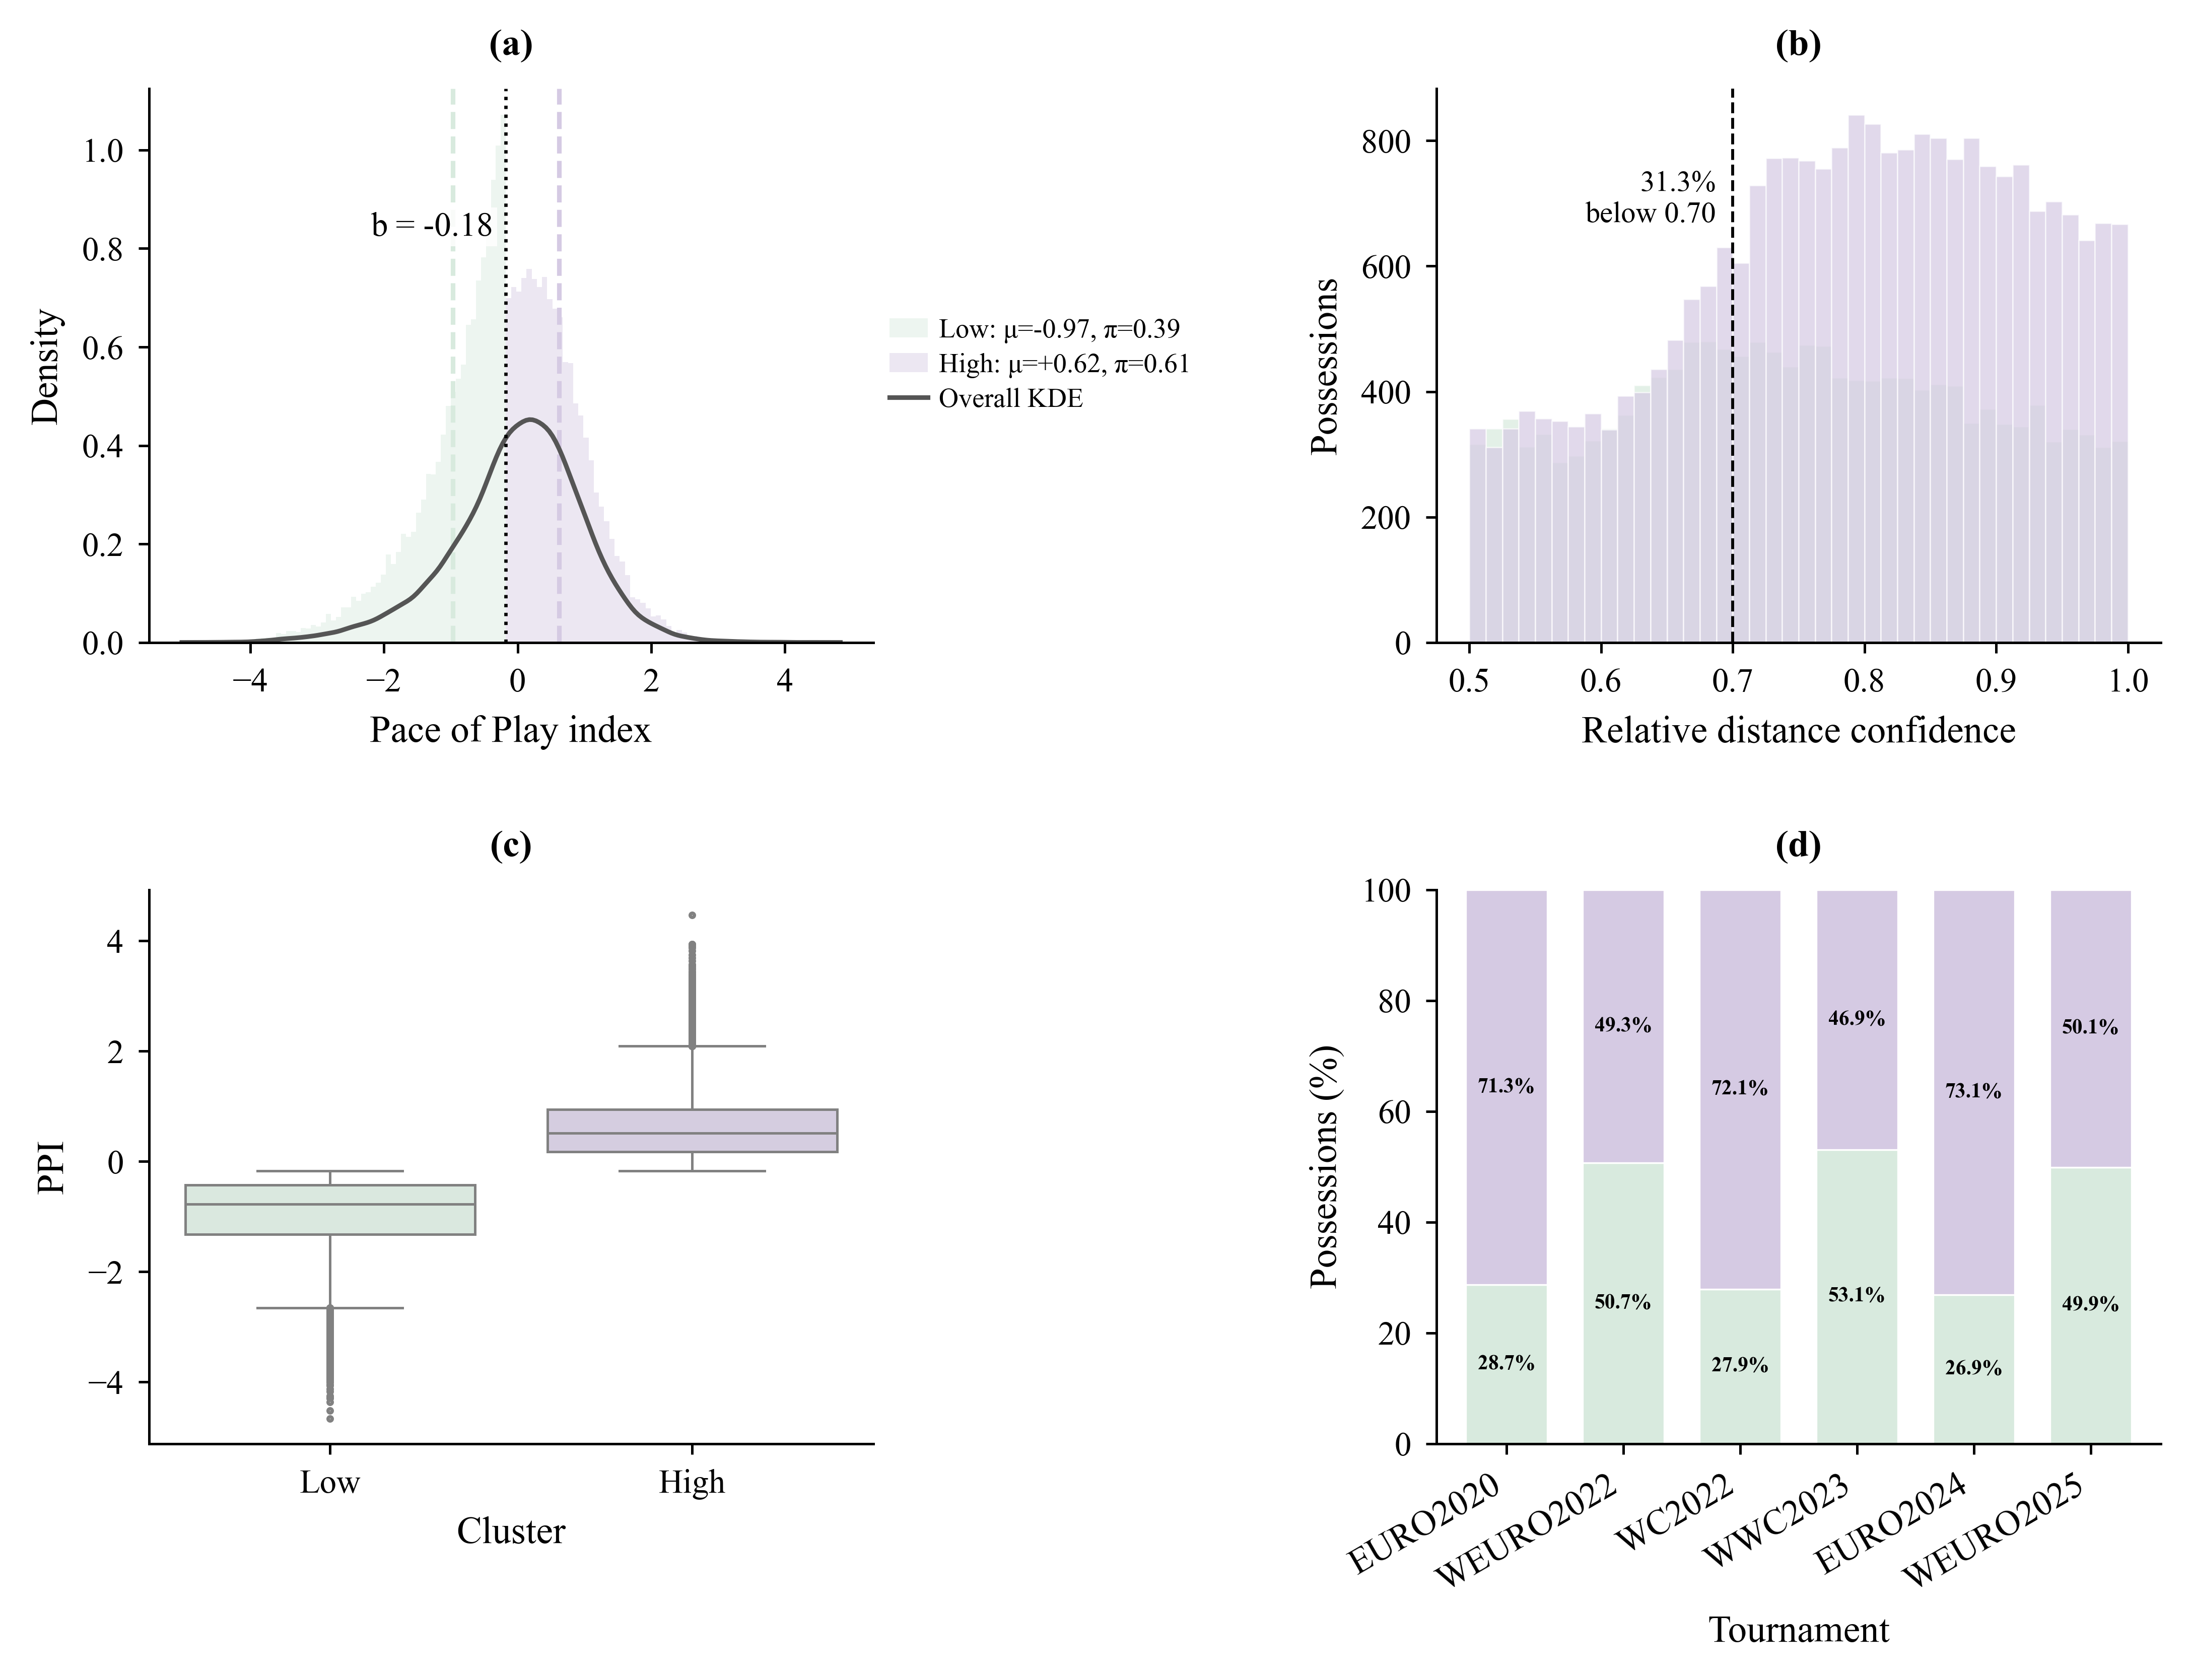

=== Assignment confidence (relative distance) ===
  mean = 0.771   median = 0.778
  31.3% rows confidence < 0.70
  13.4% rows confidence < 0.60

=== Decision boundaries on PPI ===
  PPI* = -0.177

=== χ²(gender × cluster) ===
  χ² = 2,388.0   dof = 1   p = 0.00e+00

=== Cluster composition (% within row) ===

• gender:
cluster   Low  High
gender             
Men      27.8  72.2
Women    51.8  48.2

• tournament (chronological):
cluster      Low  High
tournament            
EURO2020    28.7  71.3
WEURO2022   50.7  49.3
WC2022      27.9  72.1
WWC2023     53.1  46.9
EURO2024    26.9  73.1
WEURO2025   49.9  50.1


In [8]:
%config InlineBackend.figure_format = 'retina'
from scipy.stats import norm, chi2_contingency
import matplotlib as mpl

mpl.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Times New Roman"],
    "font.size":          9,
    "axes.titlesize":     10,
    "axes.labelsize":     9,
    "xtick.labelsize":    8,
    "ytick.labelsize":    8,
    "legend.fontsize":    8,
    "axes.linewidth":     0.6,
    "xtick.major.width":  0.6,
    "ytick.major.width":  0.6,
    "xtick.major.size":   2.5,
    "ytick.major.size":   2.5,
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "legend.frameon":     False,
    "savefig.dpi":        300,
    "figure.dpi":         300
})

CLUSTER_COLOURS = {
    0: "#d8eade", 
    1: "#d5cae3",  
}
palette = [CLUSTER_COLOURS[k] for k in range(K_OPT_HORST)]
MIX_COLOUR = "#000000"   # mixture density — black
KDE_COLOUR = "#555555"   # empirical KDE — dark grey
HIST_COLOUR = "#BBBBBB"  # empirical histogram — light grey

K  = K_OPT_HORST
ti = result_horst["TI_horst"].values
mu, sd, pi = cluster_mu, cluster_sd, cluster_pi

xs = np.linspace(ti.min(), ti.max(), 4000)
xs_lab = np.vectorize(_remap.get)(final_model_horst.predict(xs.reshape(-1, 1)))
transitions = np.where(np.diff(xs_lab) != 0)[0]
_p1, _p99 = np.percentile(ti, [1, 99])
boundaries = [b for b in np.unique(xs[transitions].round(3)) if _p1 <= b <= _p99]

# ── figure: two-column width 180 mm × 110 mm 
fig, ax = plt.subplots(2, 2, figsize=(7.09, 5.4), constrained_layout=True)

fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.10, hspace=0.10)

def panel_label(ax_, letter):
    ax_.set_title(f"({letter})", loc="center",
                  fontsize=9, fontweight="bold", pad=8)

# ── (a)  Selected-model partition 
a = ax[0, 0]
for k in range(K):
    sub = result_horst.loc[result_horst['cluster'] == k, 'TI_horst']
    comp_label = "Low" if k == 0 else "High"
    a.hist(sub, bins=60, density=True, color=palette[k], alpha=0.45,
           edgecolor='none', label=f"{comp_label}: μ={mu[k]:+.2f}, π={pi[k]:.2f}")
    a.axvline(mu[k], color=palette[k], ls='--', lw=1.1)
sns.kdeplot(ti, ax=a, color=KDE_COLOUR, lw=1.1, label='Overall KDE')
for b in boundaries:
    a.axvline(b, color=MIX_COLOUR, ls=":", lw=0.8)
    a.annotate(f"b = {b:+.2f}",
            xy=(b, a.get_ylim()[1]*0.75),
            xytext=(-3, 0),
            textcoords="offset points",
            fontsize=8,
            fontfamily="Times New Roman",
            va="center",
            ha="right",
            bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Pace of Play index")
a.set_ylabel("Density")
a.legend(loc="center left", bbox_to_anchor=(1.00, 0.5),
         handlelength=1.4, handletextpad=0.4, borderaxespad=0.2,
         labelspacing=0.35, fontsize=6.5)
panel_label(a, "a")

# ── (b)  Relative-distance assignment confidence by cluster
a = ax[0, 1]
for k in range(K):
    sub = result_horst.loc[result_horst["cluster"]==k, "assignment_confidence"]
    comp_label = "Low" if k == 0 else "High"
    a.hist(sub, bins=40, alpha=0.7, color=palette[k],
           label=comp_label, edgecolor="white", linewidth=0.3)
a.axvline(0.70, color="black", ls="--", lw=0.7)
low_conf = (result_horst["assignment_confidence"] < 0.70).mean() * 100
a.annotate(f"{low_conf:.1f}%\nbelow 0.70",
           xy=(0.70, a.get_ylim()[1]*0.80), xytext=(-4, 0),
           textcoords="offset points",
           fontsize=7, ha="right", va="center",
           bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
a.set_xlabel("Relative distance confidence")
a.set_ylabel("Possessions")
panel_label(a, "b")

# ── (c)  Within-cluster PPI boxplot
a = ax[1, 0]
sns.boxplot(data=result_horst, x="cluster", y="TI_horst", hue="cluster",
            palette=palette, ax=a, fliersize=0.8, linewidth=0.6,
            legend=False)
a.set_xlabel("Cluster")
a.set_ylabel("PPI")
a.set_xticks(range(K)); a.set_xticklabels(["Low", "High"])
panel_label(a, "c")

# Gender composition is retained for the χ² analysis but not plotted.
g_comp = (pd.crosstab(result_horst["gender"], result_horst["cluster"],
                      normalize="index") * 100).round(1)
g_comp = g_comp.rename(columns={0: "Low", 1: "High"})
ct = pd.crosstab(result_horst["gender"], result_horst["cluster"])
chi2, p_val, dof, _ = chi2_contingency(ct)

# ── (d)  Cluster composition by tournament (stacked %) 
a = ax[1, 1]
t_comp = (pd.crosstab(result_horst["tournament"], result_horst["cluster"],
                      normalize="index") * 100).round(1)
t_comp = t_comp.rename(columns={0: "Low", 1: "High"})
tournament_timeline = ["EURO2020", "WEURO2022", "WC2022",
                       "WWC2023", "EURO2024", "WEURO2025"]
t_comp = t_comp.loc[[t for t in tournament_timeline if t in t_comp.index]]
t_comp.plot(kind="bar", stacked=True, color=palette, ax=a,
            width=0.7, edgecolor="white", linewidth=0.4, legend=False)
for c in a.containers:
    a.bar_label(c, label_type="center", fmt="%.1f%%",
                fontsize=5, color="black", fontweight="bold")
a.set_xlabel("Tournament"); a.set_ylabel("Possessions (%)")
a.set_ylim(0, 100)
a.tick_params(axis="x", rotation=30, labelsize=8.5)
for lbl in a.get_xticklabels():
    lbl.set_horizontalalignment("right")
panel_label(a, "d")

for r in ax:
    for a in r:
        sns.despine(ax=a, trim=False)

os.makedirs("figures", exist_ok=True)
fig.savefig("figures/Figure_cluster_diagnostics.png", dpi=300,
            bbox_inches="tight")
plt.show()

# ── Text summary 
print(f"=== Assignment confidence ({confidence_type}) ===")
print(f"  mean = {result_horst['assignment_confidence'].mean():.3f}   "
      f"median = {result_horst['assignment_confidence'].median():.3f}")
print(f"  {(result_horst['assignment_confidence']<0.70).mean()*100:.1f}% rows confidence < 0.70")
print(f"  {(result_horst['assignment_confidence']<0.60).mean()*100:.1f}% rows confidence < 0.60")
print(f"\n=== Decision boundaries on PPI ===")
for b in boundaries:
    print(f"  PPI* = {b:+.3f}")
print(f"\n=== χ²(gender × cluster) ===")
print(f"  χ² = {chi2:,.1f}   dof = {dof}   p = {p_val:.2e}")
print(f"\n=== Cluster composition (% within row) ===")
print("\n• gender:")
print(g_comp.to_string())
print("\n• tournament (chronological):")
print(t_comp.to_string())

## Match-time distribution of pace of play

To illustrate how *Slow* and *High* pace possessions distribute across a full 90-minute match, we select
the final of each tournament and partition possessions into fixed 5-minute windows. Each panel shows the
percentage of possessions classified as *Slow* (orange) or *High* (blue) within each window.


Selected finals:
  tournament  game_id
0   EURO2020  3795506
1   EURO2024  3943043
2     WC2022  3869685
3  WEURO2022  3847567
4  WEURO2025  4020846
5    WWC2023  3906390


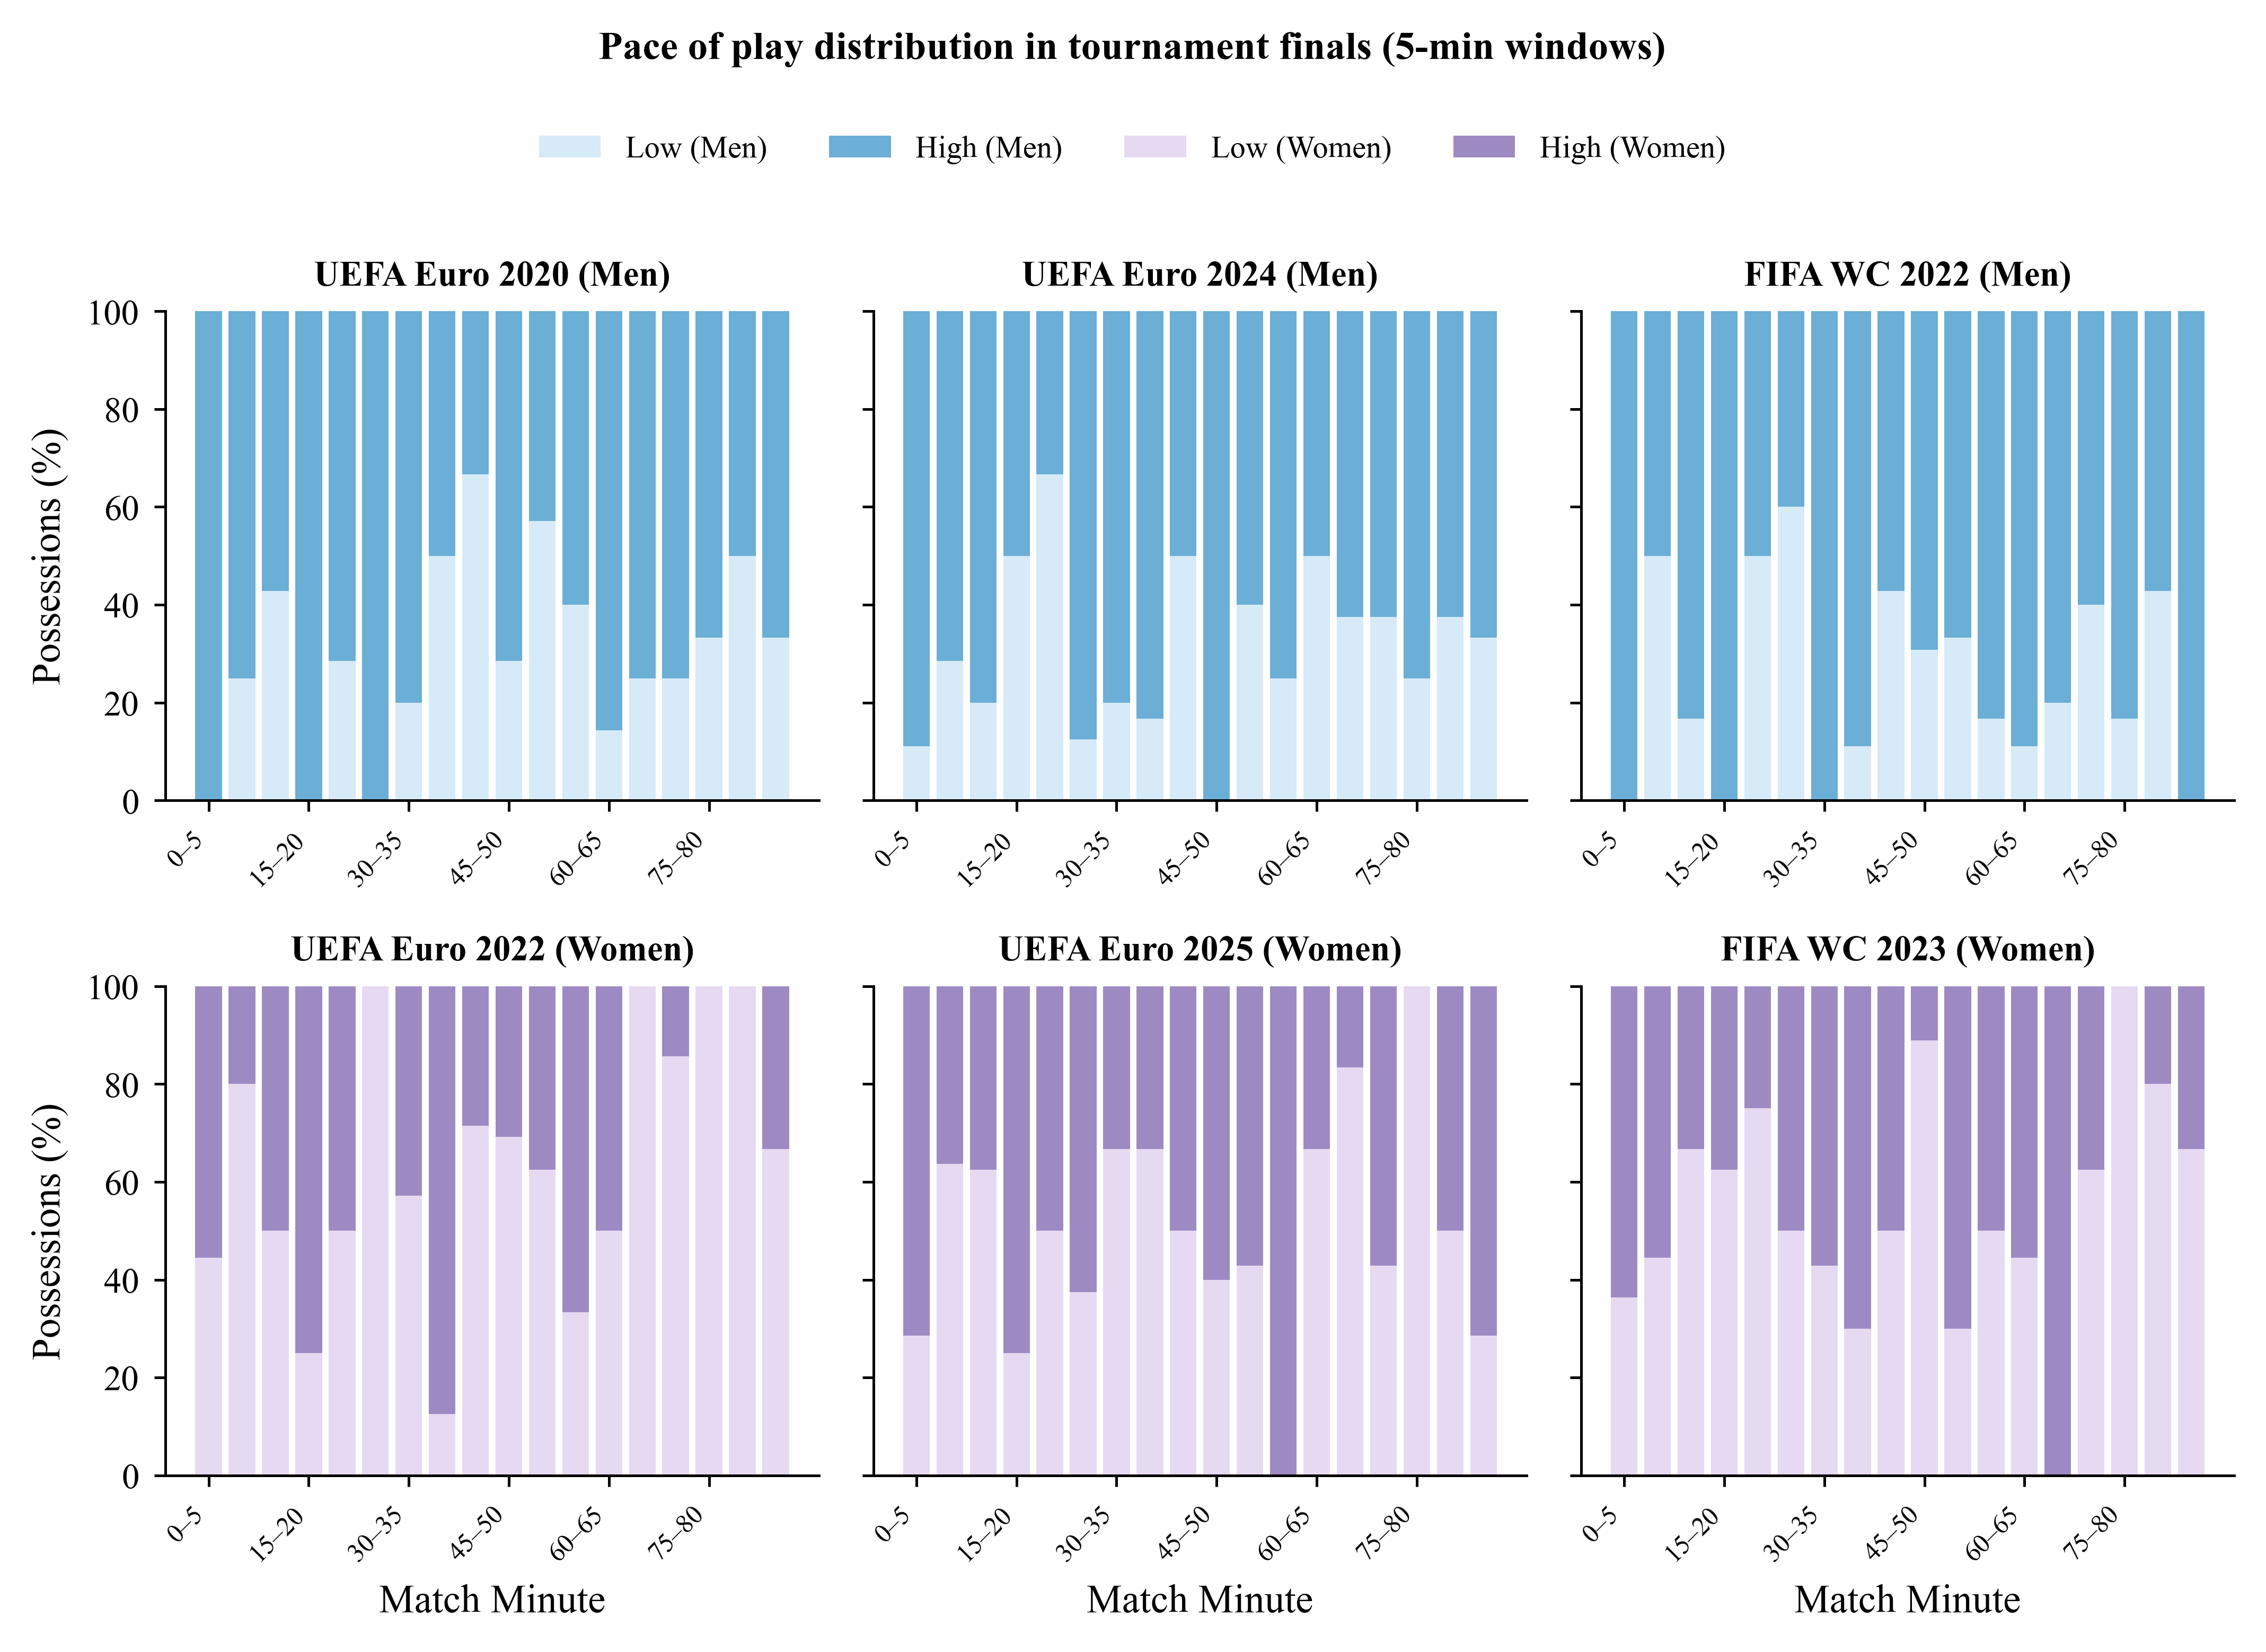

In [9]:
men_h5 = os.path.join(datafolder, "men-statsbomb.h5")

# 1. Use the selected in-memory clustering results (avoids loading stale labels).
df_cluster = result_horst.copy()

# 2. Select the final of each tournament
final_games = pd.DataFrame({
    "tournament": ["EURO2020", "EURO2024", "WC2022", "WEURO2022", "WEURO2025", "WWC2023"],
    "game_id":    [3795506,    3943043,    3869685, 3847567,     4020846,     3906390],
})
print("Selected finals:"); print(final_games)

# 3. Filter to selected games
df_sel = df_cluster.merge(final_games, on=["tournament", "game_id"])

# 4. Extract possession start times from raw events
possession_times = []
for row in df_sel[["game_id", "gender"]].drop_duplicates().itertuples():
    gid = row.game_id
    h5_file = men_h5 if row.gender == "Men" else spadl_h5
    try:
        events = pd.read_hdf(h5_file, f"events/game_{gid}")
        first_ev = (events[["possession", "minute", "second"]]
                    .groupby("possession").first().reset_index())
        first_ev["game_id"] = gid
        possession_times.append(first_ev)
    except Exception as e:
        print(f"  Error game {gid}: {e}")

all_times = pd.concat(possession_times, ignore_index=True)
df_sel = df_sel.merge(all_times, on=["game_id", "possession"], how="inner")
df_sel["match_minute"] = df_sel["minute"] + df_sel["second"] / 60.0

# 5. Remove possessions beyond 90 min
df_sel = df_sel[df_sel["match_minute"] <= 90].copy()

# 6. Create 5-minute bins (0-90 only, 18 bins)
bin_edges = list(range(0, 91, 5))  # [0, 5, 10, ..., 90]
labels_5 = [f"{bin_edges[i]}–{bin_edges[i+1]}" for i in range(len(bin_edges)-1)]
df_sel["minute_bin"] = pd.cut(df_sel["match_minute"], bins=bin_edges,
                               labels=labels_5, include_lowest=True)

df_sel["pace_label"] = df_sel["cluster"].map({0: "Low", 1: "High"})

# 7. Counts → percentages per bin
ct = (df_sel.groupby(["tournament", "minute_bin", "pace_label"], observed=False)
      .size().unstack(fill_value=0))
for col in ["Low", "High"]:
    if col not in ct.columns:
        ct[col] = 0
ct = ct[["Low", "High"]]
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

# 8. Plot – 6 subplots (2 rows × 3 cols)
tourn_order = ["EURO2020", "EURO2024", "WC2022", "WEURO2022", "WEURO2025", "WWC2023"]
tourn_labels = {
    "EURO2020": "UEFA Euro 2020 (Men)",
    "EURO2024": "UEFA Euro 2024 (Men)",
    "WC2022":   "FIFA WC 2022 (Men)",
    "WEURO2022":"UEFA Euro 2022 (Women)",
    "WEURO2025":"UEFA Euro 2025 (Women)",
    "WWC2023":  "FIFA WC 2023 (Women)",
}

men_colours  = {"Low": "#D6EAF7", "High": "#6BAED6"}  
women_colours = {"Low": "#E6DAF2", "High": "#9E8AC3"} 
women_tourns = {"WEURO2022", "WEURO2025", "WWC2023"}

fig, axes = plt.subplots(2, 3, figsize=(7.2, 4.8), dpi=300, sharey=True)

for idx, tourn in enumerate(tourn_order):
    ax = axes.flat[idx]
    sub = ct_pct.loc[tourn]
    x = np.arange(len(sub))
    bar_w = 0.8
    pal = women_colours if tourn in women_tourns else men_colours

    ax.bar(x, sub["Low"], width=bar_w, color=pal["Low"], label="Low")
    ax.bar(x, sub["High"], width=bar_w, bottom=sub["Low"],
           color=pal["High"], label="High")

    ax.set_title(tourn_labels.get(tourn, tourn), fontsize=8, fontweight="bold")
    ax.set_ylim(0, 100)
    ax.set_xticks(x[::3])
    ax.set_xticklabels(sub.index[::3], rotation=45, ha="right", fontsize=6)

    if idx % 3 == 0:
        ax.set_ylabel("Possessions (%)")
    if idx >= 3:
        ax.set_xlabel("Match Minute")

# Two-row legend: Men colours + Women colours
from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor=men_colours["Low"], label="Low (Men)"),
    Patch(facecolor=men_colours["High"], label="High (Men)"),
    Patch(facecolor=women_colours["Low"], label="Low (Women)"),
    Patch(facecolor=women_colours["High"], label="High (Women)"),
]
fig.legend(handles=legend_handles, loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 1.02), frameon=False, fontsize=7)

fig.suptitle("Pace of play distribution in tournament finals (5-min windows)",
             fontsize=9, fontweight="bold", y=1.07)

plt.tight_layout()
os.makedirs("figures", exist_ok=True)
plt.savefig("figures/pace_time_evolution.png", dpi=300, bbox_inches="tight")
plt.show()


## Component-feature preparation (winsorised, natural units)

Reproduces Step-1 preprocessing of `2-compute-features.ipynb` for the PPI component
features (fill structural NaN, directional sign-inversion, winsorise at [P1, P99]).
These winsorised features feed the pace-state profile below; **no z-scoring is applied
here** so the features stay in their natural units. The PPI itself is reported on the
standardised scale (`TI_horst`, mean 0, SD 1), consistent with its definition.

In [10]:
# ── Winsorised component features (natural units) for the pace-state profile ──
ALL_FEATURES = [
    "passes_per_minute", "distance_per_second", "distance_per_touch",
    "time_to_pass", "attacking_transition_time", "team_centroid_speed",
    "forward_progression_rate", "attack_rearline_variability", "team_spread_rate",
    "inter_team_longitudinal_dist", "pressing_frequency", "spatial_compression_x",
    "spatial_compression_y", "defensive_line_variability", "pass_completion_rate",
]
INVERT = {"time_to_pass", "attacking_transition_time"}          # higher = faster
FEATURES_FINAL = [                                              # 7 retained PPI components
    "passes_per_minute", "distance_per_second", "distance_per_touch",
    "time_to_pass", "spatial_compression_x", "spatial_compression_y",
    "pass_completion_rate",
]

cf = pd.read_hdf(spadl_h5, "combined_features")
raw_feat = cf[ALL_FEATURES].copy()
for col in ["attacking_transition_time", "time_to_pass"]:
    raw_feat[col] = raw_feat[col].fillna(raw_feat[col].quantile(0.95))
keep_idx = raw_feat.dropna().index
raw_feat = raw_feat.loc[keep_idx]
for col in INVERT:
    raw_feat[col] = -raw_feat[col]
for col in ALL_FEATURES:
    lo, hi = raw_feat[col].quantile(0.01), raw_feat[col].quantile(0.99)
    raw_feat[col] = raw_feat[col].clip(lo, hi)
print(f"Component features winsorised for {len(keep_idx):,} possessions.")

Component features winsorised for 39,995 possessions.


## PPI raincloud plot — tournament timeline

Possession-level Pace-of-Play (`TI_horst`, standardised: mean 0, SD 1), with all
tournaments arranged chronologically from left to right and no gender grouping.
Each raincloud combines a half-violin density (cloud), a reproducible sample of raw
possessions (rain), and a boxplot. The white dot marks the mean; the box and centre
line show the IQR and median, and whiskers extend to 1.5 × IQR.

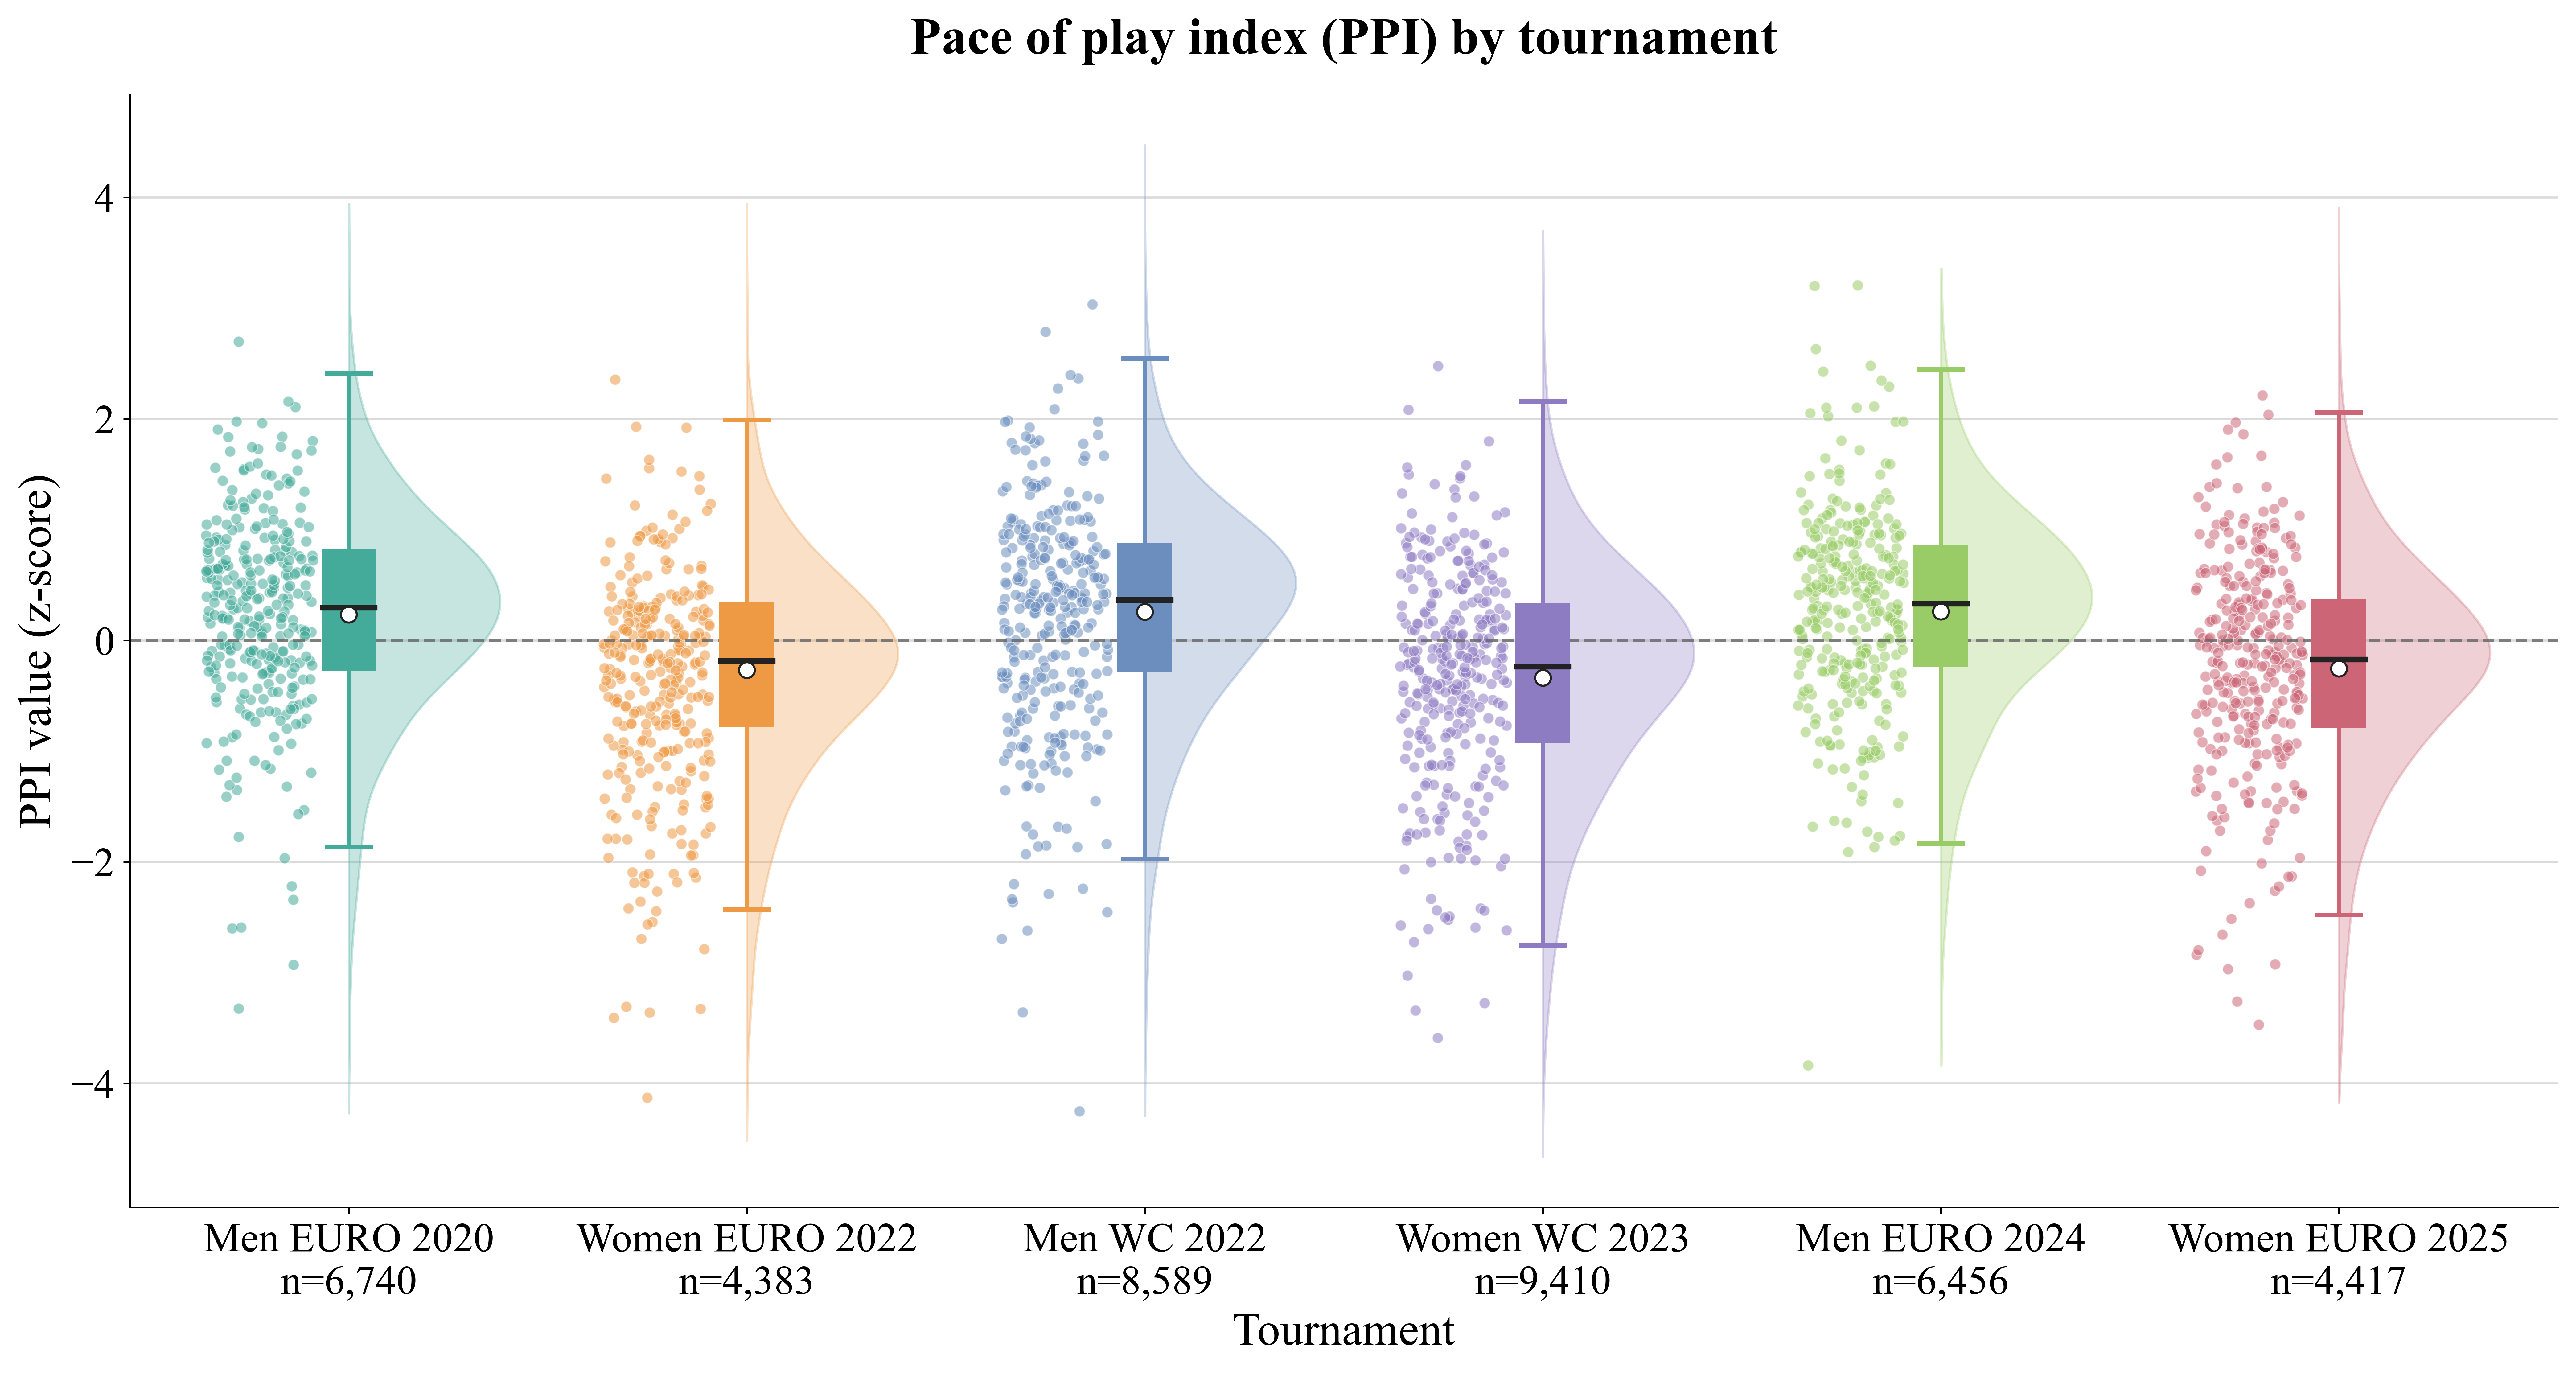

In [11]:
# ── PPI raincloud plot: chronological tournament timeline 
from matplotlib.patches import Rectangle
from scipy.stats import gaussian_kde

TOURN_LABELS = {
    "EURO2020":  "Men EURO 2020",
    "WEURO2022": "Women EURO 2022",
    "WC2022":    "Men WC 2022",
    "WWC2023":   "Women WC 2023",
    "EURO2024":  "Men EURO 2024",
    "WEURO2025": "Women EURO 2025",
}
TOURN_COLOURS = {
    "EURO2020": "#44AA99", "WEURO2022": "#EE9944", "WC2022": "#6C8EBF",
    "WWC2023": "#8E7CC3", "EURO2024": "#99CC66", "WEURO2025": "#CC6677",
}

plt.rcParams["font.family"] = "Times New Roman"
ppi = efa_df.dropna(subset=["TI_horst"]).copy()
plot_order = [t for t in TOURN_LABELS if t in set(ppi["tournament"])]
rng = np.random.default_rng(2025)

fig, ax = plt.subplots(figsize=(14, 7.5))

for x, tourn in enumerate(plot_order):
    values = ppi.loc[ppi["tournament"] == tourn, "TI_horst"].to_numpy()
    colour = TOURN_COLOURS[tourn]

    # Cloud: KDE drawn only on the right-hand side.
    y_grid = np.linspace(values.min(), values.max(), 320)
    density = gaussian_kde(values, bw_method=0.25)(y_grid)
    cloud_width = 0.38 * density / density.max()
    ax.fill_betweenx(y_grid, x, x + cloud_width, color=colour, alpha=0.30,
                     edgecolor=colour, linewidth=0.9, zorder=1)

    # Rain: plot a deterministic sample so large tournaments remain readable.
    n_points = min(320, len(values))
    rain = rng.choice(values, size=n_points, replace=False)
    rain_x = x - rng.uniform(0.09, 0.36, size=n_points)
    ax.scatter(rain_x, rain, s=18, color=colour, alpha=0.55,
               edgecolor="white", linewidth=0.35, zorder=2)

    # Box: IQR, median, 1.5 x IQR whiskers, and mean (white dot).
    q1, median, q3 = np.quantile(values, [0.25, 0.50, 0.75])
    iqr = q3 - q1
    whisker_low = values[values >= q1 - 1.5 * iqr].min()
    whisker_high = values[values <= q3 + 1.5 * iqr].max()
    box_left, box_right = x - 0.065, x + 0.065
    ax.plot([x, x], [whisker_low, q1], color=colour, linewidth=1.8, zorder=3)
    ax.plot([x, x], [q3, whisker_high], color=colour, linewidth=1.8, zorder=3)
    ax.plot([x - 0.055, x + 0.055], [whisker_low, whisker_low],
            color=colour, linewidth=1.8, zorder=3)
    ax.plot([x - 0.055, x + 0.055], [whisker_high, whisker_high],
            color=colour, linewidth=1.8, zorder=3)
    ax.add_patch(Rectangle((box_left, q1), box_right - box_left, q3 - q1,
                           facecolor=colour, edgecolor=colour, linewidth=1.2, zorder=4))
    ax.plot([box_left, box_right], [median, median], color="#222222",
            linewidth=2.2, zorder=5)
    ax.scatter(x, values.mean(), s=38, facecolor="white", edgecolor="#222222",
               linewidth=0.8, zorder=6)

labels = [f"{TOURN_LABELS[t]}\nn={sum(ppi['tournament'] == t):,}" for t in plot_order]
ax.set_xticks(range(len(plot_order)), labels)
ax.axhline(0, color="#666666", linestyle="--", linewidth=1.2, alpha=0.8)

ax.set_title("Pace of play index (PPI) by tournament", fontsize=20, fontweight="bold", pad=16)
ax.set_xlabel("Tournament", fontsize=18)
ax.set_ylabel("PPI value (z-score)", fontsize=18)

ax.tick_params(axis="both", labelsize=16)

ax.set_xlim(-0.55, len(plot_order) - 0.45)
ax.grid(axis="y", color="#D0D0D0", linewidth=0.8, alpha=0.75)
ax.set_axisbelow(True)
sns.despine(ax=ax)
plt.tight_layout()

fig.savefig("figures/Figure_PPI_by_gender_tournament.png", dpi=300, bbox_inches="tight")
plt.show()

## Team-level PPI — UEFA Women's EURO 2025

Per-team Pace-of-Play (mean ± SD of the standardised `TI_horst`) for the 2025 Women's
EURO, aggregated over each team's possessions (`possession_team_id`).

In [12]:
# ── Team-level PPI (standardised TI_horst) — UEFA Women's EURO 2025
teams_lkp = pd.read_hdf(spadl_h5, "teams")[["team_id", "team_name"]].drop_duplicates("team_id")
team_name = teams_lkp.set_index("team_id")["team_name"]

w25 = efa_df[(efa_df["gender"] == "Women") &
             (efa_df["tournament"] == "WEURO2025")].dropna(subset=["TI_horst"])

team_ppi = (w25.groupby("possession_team_id")["TI_horst"]
            .agg(n="count", mean="mean", sd="std").reset_index())
team_ppi["Team"] = (team_ppi["possession_team_id"].map(team_name)
                    .str.replace(" Women's", "", regex=False))
team_ppi["PPI, mean ± SD"] = team_ppi.apply(lambda r: f"{r['mean']:.3f} ± {r['sd']:.3f}", axis=1)
team_ppi = team_ppi.sort_values("mean", ascending=False)

table_b = (team_ppi[["Team", "n", "PPI, mean ± SD"]]
           .rename(columns={"n": "No. of possessions"}))

print(f"=== UEFA Women's EURO 2025 — team-level PPI (standardised TI_horst) "
      f"({len(table_b)} teams, {table_b['No. of possessions'].sum():,} possessions) ===")
print(table_b.to_string(index=False))
table_b.to_csv("figures/Table_PPI_WEURO2025_team_level.csv", index=False)
print("\n✅ saved → figures/Table_PPI_WEURO2025_team_level.csv")

=== UEFA Women's EURO 2025 — team-level PPI (standardised TI_horst) (16 teams, 4,417 possessions) ===
       Team  No. of possessions PPI, mean ± SD
    Belgium                 184 -0.033 ± 1.091
    England                 491 -0.119 ± 0.926
     Poland                 193 -0.139 ± 1.118
      Spain                 513 -0.178 ± 0.773
    Denmark                 171 -0.197 ± 0.974
Switzerland                 295 -0.204 ± 0.885
     France                 309 -0.231 ± 0.896
      Wales                 143 -0.232 ± 1.137
    Germany                 372 -0.234 ± 1.012
      Italy                 349 -0.241 ± 1.044
WNT Finland                 210 -0.333 ± 0.918
    Iceland                 201 -0.369 ± 1.050
Netherlands                 206 -0.372 ± 0.883
     Norway                 257 -0.388 ± 0.928
   Portugal                 200 -0.440 ± 0.890
     Sweden                 323 -0.494 ± 1.066

✅ saved → figures/Table_PPI_WEURO2025_team_level.csv


## Pace-state profile & per-feature thresholds

One table characterising the low vs high Pace state (selected K-means K=2 model on `TI_horst`) across the 7
PPI component features. Features are winsorised at [P1, P99] and shown in natural units.
Per feature: mean ± SD within each state; Cohen's *d* = (mean_High − mean_Low)/pooled SD
(positive ⇒ higher in high pace; `time_to_pass` is naturally negative — faster pace ⇒ less
time to release); and the Youden's *J* high-pace cut-point, with Sens / Spec / Acc showing
how well that single feature reproduces the multivariate state.

In [13]:
# ── Combined pace-state profile + per-feature Youden thresholds 
from sklearn.metrics import roc_curve

# Winsorised features in natural units, joined to the selected pace-state labels.
feat_proc = cf.loc[keep_idx, ["game_id", "possession", "possession_team_id"]].copy()
for f in FEATURES_FINAL:
    feat_proc[f] = (-raw_feat[f].values) if f in INVERT else raw_feat[f].values
prof = result_horst.merge(feat_proc, on=["game_id", "possession", "possession_team_id"])
n_lo = int((prof["cluster"] == 0).sum())
n_hi = int((prof["cluster"] == 1).sum())

def _cohen_d(a, b):
    sp = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
    return (b.mean() - a.mean()) / sp

rows = []
for f in FEATURES_FINAL:
    a = prof.loc[prof["cluster"] == 0, f].dropna()
    b = prof.loc[prof["cluster"] == 1, f].dropna()
    sub = prof[[f, "cluster"]].dropna()
    label = sub["cluster"].values                              # 1 = high pace
    score = -sub[f].values if f in INVERT else sub[f].values   # orient: higher = faster
    fpr, tpr, thr = roc_curve(label, score)
    j = int(np.argmax(tpr - fpr))                              # Youden's J
    cut = -thr[j] if f in INVERT else thr[j]                   # back to natural units
    acc = ((score >= thr[j]).astype(int) == label).mean()
    side = "<" if f in INVERT else ">"
    rows.append({
        "Variable": f,
        f"Low pace (n={n_lo:,})":  f"{a.mean():.3f} ± {a.std():.3f}",
        f"High pace (n={n_hi:,})": f"{b.mean():.3f} ± {b.std():.3f}",
        "Cohen d": round(_cohen_d(a, b), 2),
        "High-pace rule": f"{side} {cut:.2f}",
        "Sens": round(tpr[j], 3),
        "Spec": round(1 - fpr[j], 3),
        "Acc":  round(acc, 3),
    })
profile_table = pd.DataFrame(rows)

# Decision boundary on the standardised PPI axis.
model_boundaries = _decision_boundaries(final_model_horst)
boundary = round(model_boundaries[0], 3) if model_boundaries else float("nan")

print(f"=== Pace-state profile & per-feature thresholds ({METHOD_LABELS[CLUSTERING_METHOD]} K={K_OPT_HORST}) ===")
print(f"Low pace n={n_lo:,} | High pace n={n_hi:,} | "
      f"slow/fast boundary at TI_horst = {boundary}")
print(profile_table.to_string(index=False))

=== Pace-state profile & per-feature thresholds (K-means K=2) ===
Low pace n=15,490 | High pace n=24,505 | slow/fast boundary at TI_horst = -0.175
             Variable Low pace (n=15,490) High pace (n=24,505)  Cohen d High-pace rule  Sens  Spec   Acc
    passes_per_minute      15.477 ± 5.977       22.211 ± 7.419     0.98        > 16.83 0.797 0.631 0.733
  distance_per_second       7.932 ± 2.407        9.326 ± 2.465     0.57         > 7.60 0.782 0.482 0.666
   distance_per_touch      12.445 ± 6.013       14.123 ± 6.149     0.28        > 10.27 0.771 0.390 0.624
         time_to_pass       4.603 ± 1.679        3.055 ± 1.015    -1.18         < 3.84 0.831 0.632 0.754
spatial_compression_x       7.527 ± 1.519        9.153 ± 1.702     1.00         > 8.20 0.716 0.678 0.701
spatial_compression_y      12.478 ± 2.583       15.417 ± 2.917     1.05        > 14.39 0.664 0.765 0.703
 pass_completion_rate       0.700 ± 0.293        0.834 ± 0.176     0.59         > 0.75 0.782 0.453 0.654


## Persist clustered output

Write the labelled possession-level table to `tactical_cluster_horst` in the women H5 for downstream analysis.

In [14]:
cluster_cols = ["cluster", "assignment_confidence"]
save_cols = ["game_id", "possession", "possession_team_id",
             "tournament", "gender", "TI_horst"] + cluster_cols
out = result_horst[save_cols].copy()
out.to_hdf(spadl_h5, key="tactical_cluster_horst", mode="a", complevel=5)
print(f"✅ saved tactical_cluster_horst → {spadl_h5}  ({len(out):,} rows × {len(save_cols)} cols)")
print(out.head(3))

✅ saved tactical_cluster_horst → ../data/women-statsbomb3.h5  (39,995 rows × 8 cols)
   game_id  possession  possession_team_id tournament gender  TI_horst  \
0  4020846           2                 865  WEURO2025  Women  1.143743   
1  4020846           4                 865  WEURO2025  Women  0.737501   
2  4020846           5                 865  WEURO2025  Women  1.003642   

   cluster  assignment_confidence  
0        1               0.801131  
1        1               0.935171  
2        1               0.836920  
